# 🎃 AML Challenge 2026/27 — Notebook 4: DINOv3-**L** con le tecniche migliori (fine-tuning + ritagli + zoom) e due nuove ricette

**Cosa abbiamo imparato (nb1–nb3, val-split, IC95% ≈ ±4.8):** zero-shot DINOv3-B 0.245 → fine-tuning delle ultime layer ~0.49 → + soft/multiscala 0.50 → + **zoom a 1 giro 0.535**.

Il fine-tuning con ritagli centrati sull'oggetto batte quello su sole immagini intere; flip-TTA, 2–3 giri di zoom, ensemble A+B, ri-ranking geometrico/cycle e allineamento di posa sono neutri o negativi → **qui non ci sono**.

Il training del nb3 *memorizzava* (train 0.93 vs val 0.54) e il val calava di ~5 punti nelle ultime epoche.

---

## Cosa si testa qui

Tutto su DINOv3 **ViT-L/16**, stessa pipeline e stesso val-split del nb3, quindi i numeri sono confrontabili con la base B.

| Test | Domanda |
|:---|:---|
| **Z0 / ZM / Z1** – Zero-shot L (ultimo layer; media degli ultimi K layer; 768 px) | Il backbone più grande generalizza meglio? La media dei layer aiuta ancora? |
| **F** – Fine-tuning pieno + ritagli + zoom | Baseline L |
| **M** – F + **mix appreso dei layer** (ultimo + Σ αₖ · (layerₖ − ultimo), α = 0 all'inizio) | L'informazione locale degli strati intermedi porta maggiore precisione? |
| **L** – **LoRA** r=16 sulle K layer (pesi base congelati) | È possibile ridurre l'overfitting con pochi dati? |
| *LM = LoRA + mix (su richiesta)* | — |
| **Early stopping vero** (snapshot dell'epoca migliore, `PATIENCE`) | Evitare la perdita di 5 punti a fine training |
| **Diagnostica** (gap train/val, per scala, per n. target, oracolo top-K, tassonomia degli errori) | Dove si guadagna e dove no, rispetto a B? |

## Scelte di progetto

- Testa addestrata sul **solo train-split**; la submission usa lo snapshot validato (niente ri-addestramento su train+val: nel nb3 la schedule compressa portava in overfitting).
- Self-check a epoca 0 per **tutte** le ricette (la testa deve coincidere con DINOv3-L completo).
- Backward per unità: ViT-L non starebbe in memoria con 8 coppie nel grafo.

## ⚠️ Prima di lanciare

1. **Pesi del modello:** imposta `DINO_WEIGHTS` (cella 1, o env `AML_DINO_L`) sul `.pth` di `dinov3-vitl16-pretrain-lvd1689m` **in formato HF** (come il file del ViT-B che usavi). Se invece hai la cartella HF (config + safetensors), imposta `AML_DINO_L_DIR`. Se i pesi sono nel formato originale Meta (chiavi `blocks.*`), il caricamento si ferma con un messaggio esplicito.

2. **Smoke test:** usa `AML_QUICK=1` (20 coppie, 2 epoche, tutte e 4 le ricette, 4 coppie di test) per verificare che tutto funzioni prima del run vero. Il codice non è stato eseguito con ViT-L: il self-check (§3) è la prima linea di difesa.

3. **Tempo:** stima ~9–10 min/epoca per ricetta (≈1.8× rispetto a B). `RUN_RECIPES` (env `AML_RECIPES="F,M,L"`) permette di eseguire una ricetta per sessione; i checkpoint vengono riutilizzati.

4. **Disco/RAM:** cache token L (2.1 MB per immagine/ritaglio), circa 8–10 GB in `WORK_DIR` e ~6 GB di RAM per la cache.

## 1. Setup e configurazione

In [1]:
import os, json, math, hashlib, random, time, copy, warnings
from collections import OrderedDict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy import ndimage as ndi
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as TF
warnings.filterwarnings("ignore")

# ============================ CONFIG ============================
DATA_DIR  = os.environ.get("AML_DATA", "./aml-challenge-2026-27")
WORK_DIR  = os.environ.get("AML_WORK", "./work4")
DINO_WEIGHTS = os.environ.get("AML_DINO_L", "./weights/dinov3-vit-l16.pth")   # ⚠️ DINOv3 ViT-L/16: metti qui il path del .pth (o .safetensors)
DINO_HF_DIR  = os.environ.get("AML_DINO_L_DIR", "")   # alternativa: cartella in formato HF (config.json + model.safetensors) → from_pretrained
DINO_CFG = dict(hidden_size=1024, intermediate_size=4096, num_hidden_layers=24, num_attention_heads=16, patch_size=16, num_register_tokens=4)   # ViT-L/16
SEED, VAL_FRAC = 0, 0.25

# --- backbone / fine-tuning ---
TRUNK_MODE = os.environ.get("AML_TRUNK", "autocast")   # tronco congelato: "autocast" (pesi fp32, calcolo fp16 dove sicuro) | "fp32" (lento ma sicuro). ViT-L in fp16 puro può andare in overflow
K_TRAIN    = 4          # quante ultime layer ri-addestrare (tutte le ricette condividono la stessa cache di token)
UP         = 2          # fattore di upsampling della testa (1 = nessuno)
TRAIN_SIZE = 512        # lato lungo (px) a cui si addestra (e si mettono in cache i token)
EPOCHS, BATCH = 12, 8   # schedule più corta del nb3 (24): il val aveva il picco a metà schedule
PATIENCE, MIN_EPOCHS = 4, 5   # early stopping vero: si ferma se il val non migliora da PATIENCE epoche
LR_BLOCKS, LR_HEAD, LR_LORA, WD = 4e-5, 3e-4, 2e-4, 0.05   # LR_BLOCKS un po' più basso del nb3 (6e-5) perché il modello è più grande
LORA_R, LORA_ALPHA = 16, 32
TAU        = 0.05       # temperatura dei logit
SIGMA_MAX, SIGMA_MIN = 3.0, 1.25   # σ della gaussiana target, in celle della griglia fine (annealing coseno)
EMA_BETA   = 0.97
REVERSE_AUG = True      # coppie invertite (solo query con 1 target accettato)
CROP_SIZE  = 512        # lato lungo dei ritagli centrati sull'oggetto (training e zoom)
CROP_VARIANTS = 2       # ritagli (con jitter) per coppia usati in training
RECIPES = {"F": dict(mix="none", lora=0), "M": dict(mix="learn", lora=0), "L": dict(mix="none", lora=LORA_R), "LM": dict(mix="learn", lora=LORA_R)}
RUN_RECIPES = [r for r in os.environ.get("AML_RECIPES", "F,M,L").split(",") if r]   # quali ricette addestrare (ognuna è lunga: puoi farle in sessioni separate, i checkpoint vengono riusati)
QUICK = bool(int(os.environ.get("AML_QUICK", "0")))   # 1 = smoke test rapido (poche coppie, 2 epoche): verifica che tutto giri
# --- inferenza ---
INF_SIZES = (512, 768)  # scale per l'ensemble
CANON     = 128         # celle sul lato lungo della mappa canonica
PCK_THRS  = (0.05, 0.10, 0.20)
# ================================================================
if QUICK: EPOCHS, CROP_VARIANTS, RUN_RECIPES = 2, 1, ["F", "M", "L", "LM"]
os.makedirs(f"{WORK_DIR}/tok_cache", exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
print("device:", DEVICE, "| data:", os.path.abspath(DATA_DIR))

device: cpu | data: /home/lorenzo/Documenti/GitHub/Computer-Science-Sapienza/Advanced Machine Learning/Challenge/aml-challenge-2026-27


## 2. Dati, split senza leakage, metrica
Identici al notebook 1 (stesso `SEED` → stesso `val-split`, quindi i numeri sono confrontabili).

In [3]:
def load_split(name):
    df = pd.read_csv(f"{DATA_DIR}/{name}.csv")
    pj = json.load(open(f"{DATA_DIR}/{name}_pairs.json"))["pairs"]
    pairs = {p["pair_id"]: p for p in pj}
    df["sw"] = df.pair_id.map(lambda p: pairs[p]["source_size"][0]); df["sh"] = df.pair_id.map(lambda p: pairs[p]["source_size"][1])
    df["tw"] = df.pair_id.map(lambda p: pairs[p]["target_size"][0]); df["th"] = df.pair_id.map(lambda p: pairs[p]["target_size"][1])
    if "target_points" in df:
        df["targets"] = df.target_points.map(json.loads); df["n_targets"] = df.targets.map(len)
        df["rel_scale"] = df.scale / df[["tw", "th"]].max(axis=1)
    return df.reset_index(drop=True), pairs

tr, PAIRS_TR = load_split("train"); te, PAIRS_TE = load_split("test")
for d, ps in ((tr, PAIRS_TR), (te, PAIRS_TE)):
    assert all(np.allclose(ps[r.pair_id]["source_xy"][r.query_index], [r.source_x, r.source_y]) for r in d.itertuples())

def components(df):
    parent = {}
    def find(a):
        parent.setdefault(a, a)
        while parent[a] != a: parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for s, t in set(zip(df.source_image, df.target_image)): parent[find(s)] = find(t)
    return df.source_image.map(find)
tr["comp"] = components(tr)
rng = np.random.RandomState(SEED); comps = tr.comp.unique(); rng.shuffle(comps)
val_c, n = set(), 0
for c in comps:
    if n >= VAL_FRAC * len(tr): break
    val_c.add(c); n += (tr.comp == c).sum()
tr["is_val"] = tr.comp.isin(val_c)
assert not ((set(tr[tr.is_val].source_image) | set(tr[tr.is_val].target_image)) & (set(tr[~tr.is_val].source_image) | set(tr[~tr.is_val].target_image)))
FIT_DF, VAL_DF = tr[~tr.is_val], tr[tr.is_val]
if QUICK:
    FIT_DF = FIT_DF[FIT_DF.pair_id.isin(FIT_DF.pair_id.unique()[:20])]; VAL_DF = VAL_DF[VAL_DF.pair_id.isin(VAL_DF.pair_id.unique()[:6])]
VAL_MASK = tr.index.isin(VAL_DF.index)
print(f"train: {len(tr)} query | train-split {len(FIT_DF)} | val-split {len(VAL_DF)} | test {len(te)} query, {te.pair_id.nunique()} coppie" + ("  [QUICK]" if QUICK else ""))

# dimensioni immagini per path
SIZES = {}
for d in (tr, te):
    for r in d.itertuples(): SIZES[r.source_image] = (r.sw, r.sh); SIZES[r.target_image] = (r.tw, r.th)

# ---- metrica (dalla definizione del README) ----
def norm_err(pred, targets, scale):
    return float(np.linalg.norm(np.asarray(targets, float) - np.asarray(pred, float)[None], axis=1).min() / scale)
def pck(errs, thr=0.10):
    e = np.asarray(errs, float); e = e[~np.isnan(e)]; return float((e <= thr).mean())
def boot_ci(errs, groups, thr=0.10, B=1000, seed=0):
    e = pd.Series(np.asarray(errs, float)); g = pd.Series(np.asarray(groups)); ok = e.notna().values; e, g = e[ok], g[ok]
    ids = g.unique(); by = {k: (v.values <= thr) for k, v in e.groupby(g.values)}; r = np.random.RandomState(seed); out = []
    for _ in range(B):
        s = r.choice(len(ids), len(ids)); out.append(np.concatenate([by[ids[i]] for i in s]).mean())
    return np.percentile(out, [2.5, 97.5])

RESULTS, CFGS = OrderedDict(), {}
def register(name, preds_xy):
    e = pd.Series(np.nan, index=tr.index)
    for i, r in preds_xy.iterrows(): e[i] = norm_err((r.x, r.y), tr.targets[i], tr.scale[i])
    RESULTS[name] = e; return e
def summarize(names=None, mask=None):
    mask = VAL_MASK if mask is None else mask; rows = []
    for n in (names or RESULTS):
        ee = RESULTS[n][mask]; ok = ee.notna()
        if ok.sum() == 0: continue
        lo, hi = boot_ci(ee[ok], tr.pair_id[mask][ok])
        rows.append(dict(method=n, n=int(ok.sum()), **{f"PCK@{t:.2f}": pck(ee[ok], t) for t in PCK_THRS}, CI95_10=f"[{lo:.3f},{hi:.3f}]", err_median=ee[ok].median()))
    return pd.DataFrame(rows).set_index("method")

train: 2495 query | train-split 1800 | val-split 695 | test 577 query, 98 coppie


## 3. Immagini, ritagli e backbone
Un'immagine è identificata da una **stringa-spec**: `"images/train/x.jpg"` oppure, per i ritagli dello zoom, `"images/train/x.jpg|x0,y0,x1,y1"`. Così coppie "ritagliate" sono coppie normali e tutto il resto del codice non cambia.

Il backbone è spezzato in due:
* **`Trunk`** (congelato): embedding + prime `L-K` layer. Restituisce i **token in ingresso alle ultime K layer** (messi in cache su disco/RAM, anche per la versione specchiata).
* **`Head`** (addestrabile): copia delle ultime K layer + `norm` finale + testa di upsampling (residuo zero-init → all'epoca 0 equivale al DINOv3 originale, con mappa upsamplata bilinearmente).

In [4]:
IMNET_MEAN = np.array([0.485, 0.456, 0.406], np.float32); IMNET_STD = np.array([0.229, 0.224, 0.225], np.float32)

def parse_spec(spec):
    if "|" in spec:
        p, b = spec.split("|"); return p, tuple(int(float(v)) for v in b.split(","))
    return spec, None
def open_spec(spec):
    p, box = parse_spec(spec); img = Image.open(f"{DATA_DIR}/{p}").convert("RGB")
    return img.crop(box) if box else img
def make_spec(path, box, W, H):
    x0, y0, x1, y1 = box
    return path if (x0 <= 0 and y0 <= 0 and x1 >= W and y1 >= H) else f"{path}|{x0},{y0},{x1},{y1}"

_HF = {}
def load_dino():
    if "m" in _HF: return _HF["m"]
    from transformers import DINOv3ViTConfig, DINOv3ViTModel
    if DINO_HF_DIR:
        m = DINOv3ViTModel.from_pretrained(DINO_HF_DIR); print("caricato con from_pretrained:", DINO_HF_DIR)
    else:
        m = DINOv3ViTModel(DINOv3ViTConfig(**DINO_CFG))
        if DINO_WEIGHTS.endswith(".safetensors"):
            from safetensors.torch import load_file; sd = load_file(DINO_WEIGHTS)
        else:
            sd = torch.load(DINO_WEIGHTS, map_location="cpu"); sd = sd.get("state_dict", sd) if isinstance(sd, dict) and "state_dict" in sd else sd
        if any(k.startswith("stages.") for k in sd):
            raise RuntimeError("Questi pesi sono di una ConvNeXt (chiavi 'stages.*'), non di un ViT. Serve il model.safetensors di facebook/dinov3-vitl16-pretrain-lvd1689m (chiavi 'embeddings.*', 'layer.N.*'). Esempio di chiavi nel file: " + str(list(sd.keys())[:4]))
        if any(k.startswith("blocks.") for k in sd):
            raise RuntimeError("Pesi in formato originale Meta (chiavi 'blocks.*'): servono pesi in formato HF. Scarica facebook/dinov3-vitl16-pretrain-lvd1689m in una cartella e imposta AML_DINO_L_DIR.")
        own = set(m.state_dict().keys())
        variants = [sd, {("model." + k if k.startswith("layer.") else k): v for k, v in sd.items()},          # remap del notebook 1
                    {(k[6:] if k.startswith("model.") else k): v for k, v in sd.items()}]
        best = min(variants, key=lambda d: len(own - set(d.keys())))
        miss, unexp = m.load_state_dict(best, strict=False); print("chiavi mancanti:", miss[:6], "| inattese:", unexp[:6])
        assert not [k for k in miss if "layer" in k or "embeddings" in k], "pesi non caricati! esempio di chiavi nel file: " + str(list(sd.keys())[:5])
    assert m.config.hidden_size == 1024 and m.config.num_hidden_layers == 24, f"non è un ViT-L: {m.config.hidden_size}/{m.config.num_hidden_layers}"
    print(f"DINOv3 ViT-L/16: {sum(p.numel() for p in m.parameters()) / 1e6:.0f}M parametri")
    m = m.to(DEVICE).float().eval()
    for p in m.parameters(): p.requires_grad_(False)
    _HF["m"] = m; return m

def locate_parts(m):
    # trova ModuleList delle layer, norm finale e modulo rope, qualunque sia il percorso (m.layer, m.model.layer, ...)
    name = next((n for n, mod in m.named_modules() if isinstance(mod, nn.ModuleList) and len(mod) == m.config.num_hidden_layers), None)
    assert name is not None, "ModuleList delle layer non trovata: " + str([n for n, _ in m.named_children()])
    parent = m.get_submodule(name.rsplit(".", 1)[0]) if "." in name else m
    layers = m.get_submodule(name)
    norm = getattr(parent, "norm", None) or next(mod for n, mod in m.named_modules() if n.endswith("norm") and isinstance(mod, nn.LayerNorm))
    rope = getattr(parent, "rope_embeddings", None) or next(mod for n, mod in m.named_modules() if "rope" in n.lower())
    print("layer in:", name, "| norm:", type(norm).__name__, "| rope:", type(rope).__name__)
    return layers, norm, rope

def trunk_fwd(m, x, hidden=True):
    with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda" and TRUNK_MODE == "autocast")):
        return m(pixel_values=x, output_hidden_states=hidden)

class Trunk:
    P = 16
    def __init__(s, K=K_TRAIN):
        s.m = load_dino(); s.layers, s.norm, s.rope_mod = locate_parts(s.m); s.L = len(s.layers); s.K = K; s.R = int(s.m.config.num_register_tokens)
        s.mem = OrderedDict(); s.mem_max = 3000; s._pe = {}; s.persist = False
    def grid(s, W, H, size):
        sc = size / max(W, H); return max(1, round(H * sc / s.P)), max(1, round(W * sc / s.P))
    def rope(s, gh, gw):
        if (gh, gw) not in s._pe:
            dummy = torch.zeros(1, 3, gh * s.P, gw * s.P, device=DEVICE, dtype=torch.float32)
            with torch.no_grad(): pe = s.rope_mod(dummy)
            s._pe[(gh, gw)] = tuple(t.float() for t in pe)
        return s._pe[(gh, gw)]
    @torch.no_grad()
    def _compute(s, spec, size, flip):
        img = open_spec(spec); W, H = img.size; gh, gw = s.grid(W, H, size)
        img = img.resize((gw * s.P, gh * s.P), Image.BICUBIC)
        if flip: img = ImageOps.mirror(img)
        x = (np.asarray(img, np.float32) / 255.0 - IMNET_MEAN) / IMNET_STD
        x = torch.from_numpy(x.transpose(2, 0, 1))[None].to(DEVICE)
        h = trunk_fwd(s.m, x).hidden_states[s.L - s.K][0].float()              # input delle ultime K layer: (N, C)
        if not bool(torch.isfinite(h).all()): raise FloatingPointError(f"hidden state non finiti con TRUNK_MODE={TRUNK_MODE}: imposta AML_TRUNK=fp32")
        # ViT-L ha attivazioni enormi nel flusso residuo (~1.6e5 > max fp16 = 65504): si salvano in bfloat16 (stesso range di fp32), come int16 perché numpy non ha bf16
        return h.bfloat16().view(torch.int16).cpu().numpy(), gh, gw
    def get(s, spec, size, flip):
        key = (spec, size, bool(flip))
        if key in s.mem: s.mem.move_to_end(key); return s.mem[key]
        fn = f"{WORK_DIR}/tok_cache/" + hashlib.md5(repr((key, s.K, "bf16")).encode()).hexdigest() + ".npz"
        if os.path.exists(fn):
            z = np.load(fn); a, gh, gw = z["a"], int(z["g"][0]), int(z["g"][1])
        else:
            a, gh, gw = s._compute(spec, size, flip)
            if s.persist: np.savez(fn, a=a, g=np.array([gh, gw]))      # su disco solo durante precache() (training); non per lo zoom a inferenza
        out = (torch.from_numpy(a).view(torch.bfloat16), gh, gw); s.mem[key] = out
        if len(s.mem) > s.mem_max: s.mem.popitem(last=False)
        return out
TRUNK = Trunk()
print(f"trunk: {TRUNK.L} layer, ultime {TRUNK.K} addestrabili, {TRUNK.R} register tokens")

chiavi mancanti: [] | inattese: []
DINOv3 ViT-L/16: 303M parametri
layer in: model.layer | norm: LayerNorm | rope: DINOv3ViTRopePositionEmbedding
trunk: 24 layer, ultime 4 addestrabili, 4 register tokens


In [5]:
class LoRALinear(nn.Module):
    def __init__(s, base, r, alpha):
        super().__init__(); s.base = base; s.scale = alpha / r
        s.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(s.A, a=math.sqrt(5)); s.B = nn.Parameter(torch.zeros(base.out_features, r))   # B=0 → all'inizio identico all'originale
    def forward(s, x): return s.base(x) + (x @ s.A.T @ s.B.T) * s.scale
def add_lora(module, r, alpha):
    for name, child in list(module.named_children()):
        if isinstance(child, nn.Linear): setattr(module, name, LoRALinear(child, r, alpha))
        else: add_lora(child, r, alpha)

class Head(nn.Module):
    """Ultime K layer (addestrabili) + norm + [mix appreso dei layer] + upsampling.
    mix: 'none' = solo ultimo layer | 'learn' = ultimo + Σ α_k (layer_k − ultimo), α init 0 | 'mean' = media fissa dei K layer (solo zero-shot)
    lora: 0 = fine-tuning pieno delle K layer | r>0 = LoRA di rango r su tutte le Linear delle K layer (pesi base congelati)"""
    def __init__(s, trunk, up=UP, mix="none", lora=0):
        super().__init__(); m = trunk.m; C = m.config.hidden_size
        s.layers = copy.deepcopy(trunk.layers[trunk.L - trunk.K:]).float(); s.norm = copy.deepcopy(trunk.norm).float()
        train_base = lora == 0
        for p in list(s.layers.parameters()) + list(s.norm.parameters()): p.requires_grad_(train_base)
        if lora > 0: add_lora(s.layers, lora, LORA_ALPHA)
        s.R, s.up, s.mix = trunk.R, up, mix
        if mix == "learn": s.alpha = nn.Parameter(torch.zeros(trunk.K - 1))
        s.refine = nn.Sequential(nn.Conv2d(C, 128, 1), nn.GELU(), nn.Conv2d(128, 128, 3, padding=1, groups=128), nn.GELU(), nn.Conv2d(128, C, 1))
        nn.init.zeros_(s.refine[-1].weight); nn.init.zeros_(s.refine[-1].bias)               # residuo zero-init
    def forward(s, tok, pe, gh, gw):                    # tok (B,N,C) float32 → (B,C,gh*up,gw*up) L2-normalizzate
        h = tok; outs = []
        for l in s.layers:
            o = l(h, position_embeddings=pe); h = o[0] if isinstance(o, (tuple, list)) else o
            if s.mix != "none": outs.append(h)
        last = s.norm(h)
        if s.mix == "learn": h = last + sum(a * (s.norm(o_) - last) for a, o_ in zip(s.alpha, outs[:-1]))
        elif s.mix == "mean": h = torch.stack([s.norm(o_) for o_ in outs]).mean(0)
        else: h = last
        h = h[:, 1 + s.R:]
        B, N, C = h.shape; assert N == gh * gw, (N, gh, gw)
        f = TF.normalize(h.transpose(1, 2).reshape(B, C, gh, gw), dim=1)
        if s.up > 1:
            f = TF.interpolate(f, scale_factor=s.up, mode="bilinear", align_corners=False)
            f = TF.normalize(f + s.refine(f), dim=1)
        return f

def run_head(head, spec, size, flip):
    t, gh, gw = TRUNK.get(spec, size, flip)
    return head(t[None].to(DEVICE).float(), TRUNK.rope(gh, gw), gh, gw)[0]

def sample_desc(F, pts, W, H):
    # descrittori bilineari (L2-norm) di F (C,h,w) nei punti pts (n,2) in pixel originali di un'immagine WxH
    C, h, w = F.shape
    u = torch.as_tensor(np.asarray(pts, np.float32)[:, 0] / W * w - .5, device=F.device); v = torch.as_tensor(np.asarray(pts, np.float32)[:, 1] / H * h - .5, device=F.device)
    g = torch.stack([2 * u / max(w - 1, 1) - 1, 2 * v / max(h - 1, 1) - 1], -1)[None, None]
    d = TF.grid_sample(F[None], g, align_corners=True, padding_mode="border")[0, :, 0].T
    return TF.normalize(d, dim=-1)

# ---- self-check: a epoca 0 tutte le ricette (F, M, L, LM) devono coincidere con DINOv3-L completo ----
_r0 = tr.iloc[0]; _img = open_spec(_r0.source_image); _W, _H = _img.size; _gh, _gw = TRUNK.grid(_W, _H, TRAIN_SIZE)
def selfcheck(verbose=True):
    worst = 1.0
    with torch.no_grad():
        _x = (np.asarray(_img.resize((_gw * 16, _gh * 16), Image.BICUBIC), np.float32) / 255 - IMNET_MEAN) / IMNET_STD
        _x = torch.from_numpy(_x.transpose(2, 0, 1))[None].to(DEVICE); _o = trunk_fwd(TRUNK.m, _x)
        _hs = _o.hidden_states[TRUNK.L - TRUNK.K][0].float(); _last = _o.last_hidden_state[0, -_gh * _gw:].float()
        print(f"[modo {TRUNK_MODE}] max|hidden_state| = {float(_hs.abs().max()):.3g} | finiti: {bool(torch.isfinite(_hs).all())} (ultimo layer: {bool(torch.isfinite(_last).all())})")
        if not (torch.isfinite(_hs).all() and torch.isfinite(_last).all()): return float("nan")
        _ref = TF.normalize(_last, dim=-1).reshape(_gh, _gw, -1).permute(2, 0, 1)
        _f_cmp = TF.normalize(TF.interpolate(_ref[None], scale_factor=UP, mode="bilinear", align_corners=False), dim=1)[0] if UP > 1 else _ref
        for _name, _kw in RECIPES.items():
            _h = Head(TRUNK, **_kw).to(DEVICE).eval(); _cos = (TF.normalize(run_head(_h, _r0.source_image, TRAIN_SIZE, False), dim=0) * _f_cmp).sum(0).mean().item()
            print(f"self-check ricetta {_name:2s}: coseno con DINOv3-L completo = {_cos:.4f} | parametri addestrabili {sum(p.numel() for p in _h.parameters() if p.requires_grad) / 1e6:.1f}M"); worst = min(worst, _cos) if _cos == _cos else float("nan")
            del _h
    return worst
def safe_selfcheck():
    try: return selfcheck()
    except FloatingPointError as e: print("overflow:", e); return float("nan")
_w = safe_selfcheck()
if not (_w > 0.98) and TRUNK_MODE != "fp32":
    print("→ self-check fallito: riprovo con TRUNK_MODE='fp32'"); TRUNK_MODE = "fp32"; TRUNK.mem.clear(); TRUNK._pe.clear()
    for _f in os.listdir(f"{WORK_DIR}/tok_cache"): os.remove(f"{WORK_DIR}/tok_cache/{_f}")      # la cache costruita col modo precedente non è affidabile
    _w = safe_selfcheck()
assert _w > 0.98, f"Head ≠ modello originale anche in fp32 (coseno {_w}): controlla firma layer / rope / hidden_states. Incolla qui l'output."
print("self-check OK, modo tronco:", TRUNK_MODE)

[modo autocast] max|hidden_state| = 1.57e+05 | finiti: True (ultimo layer: True)
self-check ricetta F : coseno con DINOv3-L completo = 1.0000 | parametri addestrabili 50.7M
self-check ricetta M : coseno con DINOv3-L completo = 1.0000 | parametri addestrabili 50.7M
self-check ricetta L : coseno con DINOv3-L completo = 1.0000 | parametri addestrabili 1.4M
self-check ricetta LM: coseno con DINOv3-L completo = 1.0000 | parametri addestrabili 1.4M
self-check OK, modo tronco: autocast


## 4. Unità di training: immagini intere + ritagli centrati sull'oggetto
Identiche al notebook 3 (ricetta "B": la migliore). Unità intera (+ coppia invertita per le query a target singolo) e unità-ritaglio (sorgente = bbox dei punti sorgente; target = bbox dei target GT; margini e jitter casuali).

In [6]:
def box_from(pts, W, H, margin):
    pts = np.asarray(pts, float); x0, y0 = pts.min(0); x1, y1 = pts.max(0); pad = margin * max(x1 - x0, y1 - y0, .1 * max(W, H))
    return (int(max(0, x0 - pad)), int(max(0, y0 - pad)), int(min(W, math.ceil(x1 + pad))), int(min(H, math.ceil(y1 + pad))))

def jitter_box(b, W, H, rng, frac=.08):
    x0, y0, x1, y1 = b; w, h = x1 - x0, y1 - y0; dx, dy = rng.uniform(-frac, frac) * w, rng.uniform(-frac, frac) * h
    return (int(max(0, x0 + dx)), int(max(0, y0 + dy)), int(min(W, x1 + dx)), int(min(H, y1 + dy)))

def build_units(df, pairs, reverse=REVERSE_AUG):
    units = []
    for pid, g in df.groupby("pair_id"):
        p = pairs[pid]; Ws, Hs = p["source_size"]; Wt, Ht = p["target_size"]
        pts = np.array([[r.source_x, r.source_y] for r in g.itertuples()], np.float32); tg = [list(map(list, t)) for t in g.targets]
        units.append(dict(src=p["source_image"], tgt=p["target_image"], Ws=Ws, Hs=Hs, Wt=Wt, Ht=Ht, pts=pts, tg=tg, idx=list(g.index), fwd=True, size=TRAIN_SIZE))
        if reverse:
            sel = [k for k, t in enumerate(tg) if len(t) == 1]
            if sel: units.append(dict(src=p["target_image"], tgt=p["source_image"], Ws=Wt, Hs=Ht, Wt=Ws, Ht=Hs,
                                      pts=np.array([tg[k][0] for k in sel], np.float32), tg=[[list(pts[k])] for k in sel], idx=None, fwd=False, size=TRAIN_SIZE))
    return units

def build_crop_units(df, pairs, variants=CROP_VARIANTS, seed=0, reverse=REVERSE_AUG):
    rng = np.random.RandomState(seed); units = []
    for pid, g in df.groupby("pair_id"):
        p = pairs[pid]; Ws, Hs = p["source_size"]; Wt, Ht = p["target_size"]
        sp = np.asarray(p["source_xy"], float); tall = np.array([q for ts in g.targets for q in ts], float)
        for v in range(variants):
            sb = jitter_box(box_from(sp, Ws, Hs, rng.uniform(.15, .5)), Ws, Hs, rng); tb = jitter_box(box_from(tall, Wt, Ht, rng.uniform(.15, .6)), Wt, Ht, rng)
            sw, sh, tw, th = sb[2] - sb[0], sb[3] - sb[1], tb[2] - tb[0], tb[3] - tb[1]
            if min(sw, sh, tw, th) < 48: continue
            pts, tg = [], []
            for r in g.itertuples():
                q = (r.source_x - sb[0], r.source_y - sb[1])
                if not (0 <= q[0] <= sw and 0 <= q[1] <= sh): continue
                ts = [[x - tb[0], y - tb[1]] for x, y in r.targets if 0 <= x - tb[0] <= tw and 0 <= y - tb[1] <= th]
                if ts: pts.append(q); tg.append(ts)
            if not pts: continue
            pts = np.array(pts, np.float32); ss, ts_ = make_spec(p["source_image"], sb, Ws, Hs), make_spec(p["target_image"], tb, Wt, Ht)
            units.append(dict(src=ss, tgt=ts_, Ws=sw, Hs=sh, Wt=tw, Ht=th, pts=pts, tg=tg, idx=None, fwd=True, size=CROP_SIZE))
            if reverse:
                sel = [k for k, t in enumerate(tg) if len(t) == 1]
                if sel: units.append(dict(src=ts_, tgt=ss, Ws=tw, Hs=th, Wt=sw, Ht=sh, pts=np.array([tg[k][0] for k in sel], np.float32),
                                          tg=[[list(pts[k])] for k in sel], idx=None, fwd=False, size=CROP_SIZE))
    return units

def precache(units):
    todo = {(s, u.get("size", TRAIN_SIZE)) for u in units for s in (u["src"], u["tgt"])}; TRUNK.persist = True
    for s, sz in tqdm(sorted(todo), desc="cache token (orig+specchio)", leave=False):
        for fl in (False, True): TRUNK.get(s, sz, fl)
    TRUNK.persist = False

## 5. Training con early stopping vero
Come nel notebook 3 (CE verso somma di gaussiane, σ annealed, EMA), con queste differenze:
* **early stopping**: si valuta l'EMA a ogni epoca, si tiene lo snapshot migliore e ci si ferma se non migliora da `PATIENCE` epoche (nel nb3 il val calava di 5 punti nelle ultime epoche);
* **backward per unità** (gradient accumulation): con ViT-L il grafo di 8 unità insieme non starebbe in memoria;
* parametri in 3 gruppi di LR: blocchi (`LR_BLOCKS`), LoRA (`LR_LORA`), testa/mix α (`LR_HEAD`);
* si salvano la storia (anche i pesi α del mix) e il checkpoint per ricetta.

In [6]:
def flip_unit(u):
    v = dict(u); v["pts"] = u["pts"].copy(); v["pts"][:, 0] = u["Ws"] - v["pts"][:, 0]
    v["tg"] = [[[u["Wt"] - x, y] for x, y in ts] for ts in u["tg"]]; return v

def gauss_labels(tg, Wt, Ht, h, w, sigma):
    ii, jj = torch.meshgrid(torch.arange(h, device=DEVICE), torch.arange(w, device=DEVICE), indexing="ij"); out = []
    for ts in tg:
        L = 0
        for x, y in ts: L = L + torch.exp(-((jj - (x / Wt * w - .5)) ** 2 + (ii - (y / Ht * h - .5)) ** 2) / (2 * sigma ** 2))
        L = L.reshape(-1); out.append(L / (L.sum() + 1e-8))
    return torch.stack(out)

def unit_loss(head, u, flip, sigma):
    size = u.get("size", TRAIN_SIZE); Fs = run_head(head, u["src"], size, flip); Ft = run_head(head, u["tgt"], size, flip)
    uu = flip_unit(u) if flip else u
    desc = sample_desc(Fs, uu["pts"], u["Ws"], u["Hs"]); C, h, w = Ft.shape
    logits = desc @ Ft.reshape(C, -1) / TAU
    lab = gauss_labels(uu["tg"], u["Wt"], u["Ht"], h, w, sigma)
    return -(lab * TF.log_softmax(logits, -1)).sum(1).mean()

@torch.no_grad()
def eval_units(head, units, size=TRAIN_SIZE):
    ok = []
    for u in units:
        if not u["fwd"] or u["idx"] is None: continue
        Ft = run_head(head, u["tgt"], size, False); Fs = run_head(head, u["src"], size, False); C, h, w = Ft.shape
        am = (sample_desc(Fs, u["pts"], u["Ws"], u["Hs"]) @ Ft.reshape(C, -1)).argmax(1).cpu().numpy()
        for k, i in enumerate(u["idx"]):
            a, b = divmod(int(am[k]), w); ok.append(norm_err(((b + .5) / w * u["Wt"], (a + .5) / h * u["Ht"]), tr.targets[i], tr.scale[i]) <= .1)
    return float(np.mean(ok))

def train_head(units_trn, units_val, epochs, recipe, tag="", seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    head = Head(TRUNK, **RECIPES[recipe]).to(DEVICE); ema = copy.deepcopy(head).eval()
    for p in ema.parameters(): p.requires_grad_(False)
    groups = {}
    for n, p in head.named_parameters():
        if not p.requires_grad: continue
        lr = LR_HEAD if (n.startswith("refine") or n == "alpha") else LR_LORA if (n.endswith(".A") or n.endswith(".B")) else LR_BLOCKS
        groups.setdefault(lr, []).append(p)
    opt = torch.optim.AdamW([{"params": v, "lr": k} for k, v in groups.items()], weight_decay=WD)
    spe = math.ceil(len(units_trn) / BATCH); total, warm = epochs * spe, spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * .5 * (1 + math.cos(math.pi * min(s, total) / total)))
    v0 = eval_units(ema, units_val); hist = dict(ep=[0], loss=[np.nan], val=[v0], alpha=[head.alpha.detach().cpu().tolist() if head.mix == "learn" else None]); best = (v0, copy.deepcopy(ema.state_dict()), 0)
    print(f"[{tag}] {len(units_trn)} unità, {spe} passi/epoca, {sum(p.numel() for g in groups.values() for p in g) / 1e6:.1f}M parametri addestrabili | epoca 0 (= DINOv3-L originale): val {v0:.3f}")
    for ep in range(1, epochs + 1):
        t0 = time.time(); sigma = SIGMA_MIN + .5 * (SIGMA_MAX - SIGMA_MIN) * (1 + math.cos(math.pi * (ep - 1) / max(epochs - 1, 1)))
        head.train(); order = np.random.permutation(len(units_trn)); tot = 0
        for b in range(0, len(order), BATCH):
            idx = order[b:b + BATCH]; opt.zero_grad(); n = len(idx)
            for k in idx:
                l = unit_loss(head, units_trn[k], random.random() < .5, sigma) / n; l.backward(); tot += float(l) * n
            torch.nn.utils.clip_grad_norm_([p for g in groups.values() for p in g], 1.0); opt.step(); sched.step()
            with torch.no_grad():
                for pe_, p_ in zip(ema.parameters(), head.parameters()): pe_.mul_(EMA_BETA).add_(p_.detach(), alpha=1 - EMA_BETA)
        v = eval_units(ema, units_val)
        hist["ep"].append(ep); hist["loss"].append(tot / len(order)); hist["val"].append(v); hist["alpha"].append(ema.alpha.detach().cpu().tolist() if head.mix == "learn" else None)
        if v > best[0]: best = (v, copy.deepcopy(ema.state_dict()), ep)
        dt = time.time() - t0
        print(f"[{tag}] epoca {ep:2d}/{epochs} σ={sigma:.2f} loss {hist['loss'][-1]:.3f}  val {v:.3f}" + ("  ★" if best[2] == ep else "") + f"  ({dt:.0f}s" + (f", ~{dt * epochs / 60:.0f} min per {epochs} epoche" if ep == 1 else "") + ")")
        if ep >= MIN_EPOCHS and ep - best[2] >= PATIENCE: print(f"[{tag}] early stopping: nessun miglioramento da {PATIENCE} epoche → snapshot epoca {best[2]}"); break
    ema.load_state_dict(best[1]); del opt
    return ema.eval(), best[2], hist

## 6. Motore di matching
Come nel notebook 3 (senza ensemble di teste, flip e ri-ranking, che non hanno aiutato). Restano: multiscala, soft-argmax (τ=0.03, r=3) e **zoom a 1 giro**, la combinazione che nel nb3 ha dato 0.535 con DINOv3-B.

In [7]:
class Engine:
    def __init__(s, head, max_cache=12): s.head = head.eval(); s.lru = OrderedDict(); s.max = max_cache
    @torch.no_grad()
    def F(s, spec, size, flip):
        k = (spec, size, bool(flip))
        if k in s.lru: s.lru.move_to_end(k); return s.lru[k]
        f = run_head(s.head, spec, size, flip); s.lru[k] = f
        if len(s.lru) > s.max: s.lru.popitem(last=False)
        return f

def canon_shape(Wt, Ht): sc = CANON / max(Wt, Ht); return max(2, round(Ht * sc)), max(2, round(Wt * sc))
def cell_to_xy(i, j, Hc, Wc, Wt, Ht): return (j + .5) / Wc * Wt, (i + .5) / Hc * Ht

@torch.no_grad()
def view_map(eng, pair, size):
    Ws, Hs = pair["source_size"]; Wt, Ht = pair["target_size"]
    Fs, Ft = eng.F(pair["source_image"], size, False), eng.F(pair["target_image"], size, False)
    q = np.asarray(pair["source_xy"], np.float32); C, h, w = Ft.shape
    S = (sample_desc(Fs, q, Ws, Hs) @ Ft.reshape(C, -1)).reshape(-1, 1, h, w); Hc, Wc = canon_shape(Wt, Ht)
    return TF.interpolate(S, size=(Hc, Wc), mode="bicubic", align_corners=False)[:, 0]

def decode_argmax(S, Wt, Ht): i, j = np.unravel_index(np.argmax(S), S.shape); return cell_to_xy(i, j, *S.shape, Wt, Ht)
def decode_soft(S, Wt, Ht, tau=.03, rad=3):
    Hc, Wc = S.shape; i0, j0 = np.unravel_index(np.argmax(S), S.shape)
    i1, i2, j1, j2 = max(0, i0 - rad), min(Hc, i0 + rad + 1), max(0, j0 - rad), min(Wc, j0 + rad + 1)
    w = np.exp((S[i1:i2, j1:j2] - S[i0, j0]) / tau); w /= w.sum(); ii, jj = np.meshgrid(np.arange(i1, i2), np.arange(j1, j2), indexing="ij")
    return cell_to_xy((w * ii).sum(), (w * jj).sum(), Hc, Wc, Wt, Ht)
def top_peaks(S, K=5, nms=6):
    S2 = S.copy(); out = []
    for _ in range(K):
        if not np.isfinite(S2).any(): break
        i, j = np.unravel_index(np.argmax(S2), S2.shape); out.append((i, j, S[i, j])); S2[max(0, i - nms):i + nms + 1, max(0, j - nms):j + nms + 1] = -np.inf
    return out

@torch.no_grad()
def pair_maps(pair, eng, cfg):
    sizes = cfg.get("sizes", (TRAIN_SIZE,)); return (sum(view_map(eng, pair, sz) for sz in sizes) / len(sizes)).cpu().numpy()

@torch.no_grad()
def predict_pair(pair, eng, cfg):
    Wt, Ht = pair["target_size"]; maps = pair_maps(pair, eng, cfg)
    if cfg.get("decode", "argmax") == "soft": return np.array([decode_soft(S, Wt, Ht, cfg.get("tau", .03), cfg.get("rad", 3)) for S in maps])
    return np.array([decode_argmax(S, Wt, Ht) for S in maps])

def predict_pair_zoom(pair, eng, cfg):
    out = predict_pair(pair, eng, cfg); z = cfg.get("zoom")
    if not z or len(out) < 3: return out
    Ws, Hs = pair["source_size"]; Wt, Ht = pair["target_size"]; pts = np.asarray(pair["source_xy"], float)
    core = np.percentile(out, [10, 90], axis=0) if len(out) >= 5 else np.array([out.min(0), out.max(0)])
    sb, tb = box_from(pts, Ws, Hs, z["margin"]), box_from(core, Wt, Ht, z["margin"])
    fs, ft = (sb[2] - sb[0]) * (sb[3] - sb[1]) / (Ws * Hs), (tb[2] - tb[0]) * (tb[3] - tb[1]) / (Wt * Ht)
    if max(fs, ft) > z["max_frac"] or min(sb[2] - sb[0], sb[3] - sb[1], tb[2] - tb[0], tb[3] - tb[1]) < 32: return out
    pair2 = dict(source_image=make_spec(pair["source_image"], sb, Ws, Hs), target_image=make_spec(pair["target_image"], tb, Wt, Ht),
                 source_size=[sb[2] - sb[0], sb[3] - sb[1]], target_size=[tb[2] - tb[0], tb[3] - tb[1]], source_xy=(pts - np.array(sb[:2])).tolist())
    return predict_pair(pair2, eng, dict(cfg, sizes=z["sizes"], zoom=None)) + np.array(tb[:2])

def run(name, cfg, eng, df=None):
    df = VAL_DF if df is None else df; rows = {}
    for pid in tqdm(df.pair_id.unique(), desc=name, leave=False):
        out = predict_pair_zoom(PAIRS_TR[pid], eng, cfg)
        for i, r in df[df.pair_id == pid].iterrows(): rows[i] = out[r.query_index]
    register(name, pd.DataFrame(rows, index=["x", "y"]).T); CFGS[name] = (cfg, eng); return summarize([name], mask=tr.index.isin(df.index)).iloc[0]

def plot_summary(names, title="", extra=None):
    t = summarize(names); ci = np.array([[float(x) for x in s.strip("[]").split(",")] for s in t.CI95_10]); v = t["PCK@0.10"].values; lab = list(t.index)
    y = np.arange(len(t) + len(extra or {}))[::-1]; fig, ax = plt.subplots(figsize=(9, .42 * len(y) + 1.8))
    ax.barh(y[:len(t)], v, xerr=[v - ci[:, 0], ci[:, 1] - v], color="C0", alpha=.85, capsize=3)
    if extra: ax.barh(y[len(t):], list(extra.values()), color="gray", alpha=.6); lab += list(extra.keys()); v = np.r_[v, list(extra.values())]
    ax.set_yticks(y); ax.set_yticklabels(lab, fontsize=8)
    for yy, vv in zip(y, v): ax.text(vv + .004, yy, f"{vv:.3f}", va="center", fontsize=8)
    ax.axvline(.60, c="r", ls="--", lw=1); ax.set_xlim(max(0, v.min() - .08), min(1, max(v.max() + .06, .62))); ax.set_xlabel("PCK@0.10 su val-split (IC95% per coppia) — rosso = 0.60; grigio = DINOv3-B del nb3"); ax.set_title(title); plt.tight_layout(); plt.show()
def best_of(names): t = summarize(names); return t["PCK@0.10"].idxmax()

SOFT = dict(decode="soft", tau=.03, rad=3); BASE = dict(sizes=INF_SIZES, **SOFT)
ZOOM1 = dict(margin=.3, max_frac=.9, sizes=(CROP_SIZE, 768))
REF_B = {"[B nb3] zero-shot argmax 512": .245, "[B nb3] fine-tuned argmax 512": .489, "[B nb3] soft + multiscala": .501, "[B nb3] + zoom 1 giro": .535}
print("motore pronto")

motore pronto


## 7. Zero-shot DINOv3-L
Due test economici (nessun training):
* **Z0**: ultimo layer, argmax a 512 — da confrontare con 0.245 di DINOv3-B;
* **ZM**: *media fissa degli ultimi K layer* (nel nb1 con DINOv3-B dava +5 punti rispetto al solo ultimo layer).

In [8]:
HEAD0 = Head(TRUNK, mix="none").to(DEVICE).eval(); HEADZM = Head(TRUNK, mix="mean").to(DEVICE).eval(); ENG0, ENGZM = Engine(HEAD0), Engine(HEADZM)
run("Z0 · L zero-shot argmax 512", dict(sizes=(512,)), ENG0)
run("ZM · L zero-shot media ultimi K layer, argmax 512", dict(sizes=(512,)), ENGZM)
run("Z1 · L zero-shot argmax 768", dict(sizes=(768,)), ENG0)
display(summarize().style.format(precision=3))

Z0 · L zero-shot argmax 512:   0%|          | 0/102 [00:00<?, ?it/s]

ZM · L zero-shot media ultimi K layer, argmax 512:   0%|          | 0/102 [00:00<?, ?it/s]

Z1 · L zero-shot argmax 768:   0%|          | 0/102 [00:00<?, ?it/s]

,n,PCK@0.05,PCK@0.10,PCK@0.20,CI95_10,err_median
method,,,,,,
Z0 · L zero-shot argmax 512,695,0.131,0.273,0.567,"[0.234,0.311]",0.168
"ZM · L zero-shot media ultimi K layer, argmax 512",695,0.111,0.253,0.447,"[0.214,0.289]",0.246
Z1 · L zero-shot argmax 768,695,0.163,0.289,0.574,"[0.252,0.325]",0.164


## 8. Ricette e training
Tutte con ritagli (ricetta B del nb3), early stopping, train-split, K=`K_TRAIN` layer addestrabili:

| Ricetta | Cosa | Ipotesi |
|---|---|---|
| **F** | fine-tuning pieno | baseline (= nb3 con ViT-L) |
| **M** | F + **mix appreso dei layer** (α init 0) | recupera informazione locale degli strati intermedi → più precisione |
| **L** | **LoRA** (r=16) su tutte le Linear delle K layer | meno overfitting (nel nb3 gap train/val 0.93 vs 0.54) |
| LM | LoRA + mix | solo se M e L aiutano entrambe |

Per ogni ricetta si valutano: `…0` argmax 512, `…1` soft + multiscala 512/768, `…2` + zoom 1 giro.
**Stima tempi** (da nb3: ~310 s/epoca per ViT-B con questi dati; ViT-L ≈ 1.8× → ~9–10 min/epoca): fino a ~2 h per ricetta, meno con l'early stopping. I checkpoint (`headL_<ricetta>.pt`) vengono riusati: se la sessione si interrompe, rilancia la cella.

In [9]:
UN_FULL = build_units(FIT_DF, PAIRS_TR); UN_CROP = build_crop_units(FIT_DF, PAIRS_TR); UN_VAL = build_units(VAL_DF, PAIRS_TR, reverse=False)
print(f"unità: intere {len(UN_FULL)} | ritagli {len(UN_CROP)} | val {len(UN_VAL)} | ricette da eseguire: {RUN_RECIPES}")
precache(UN_FULL + UN_CROP + UN_VAL)
HEADS, HISTS, BEST_EP, ENGS, RNAMES = {}, {}, {}, {}, {}
for rec in RUN_RECIPES:
    ck, hk = f"{WORK_DIR}/headL_{rec}.pt", f"{WORK_DIR}/histL_{rec}.json"
    if os.path.exists(ck) and os.path.exists(hk) and not QUICK:
        h = Head(TRUNK, **RECIPES[rec]).to(DEVICE); h.load_state_dict(torch.load(ck, map_location=DEVICE)); HEADS[rec] = h.eval(); HISTS[rec] = json.load(open(hk)); BEST_EP[rec] = int(np.argmax(HISTS[rec]["val"])); print(f"[{rec}] checkpoint caricato (epoca migliore {BEST_EP[rec]})")
    else:
        HEADS[rec], BEST_EP[rec], HISTS[rec] = train_head(UN_FULL + UN_CROP, UN_VAL, EPOCHS, rec, tag=rec)
        torch.save(HEADS[rec].state_dict(), ck); json.dump(HISTS[rec], open(hk, "w"))
    ENGS[rec] = Engine(HEADS[rec]); RNAMES[rec] = [f"{rec}0 · argmax 512", f"{rec}1 · soft + multiscala", f"{rec}2 · + zoom 1 giro"]
    run(RNAMES[rec][0], dict(sizes=(512,)), ENGS[rec]); run(RNAMES[rec][1], BASE, ENGS[rec]); run(RNAMES[rec][2], dict(BASE, zoom=ZOOM1), ENGS[rec])
    display(summarize(RNAMES[rec]).style.format(precision=3))
    if HEADS[rec].mix == "learn": print(f"[{rec}] pesi α del mix (layer −{TRUNK.K}…−2 verso l'ultimo; 0 = solo ultimo layer):", np.round(HEADS[rec].alpha.detach().cpu().numpy(), 3))
    torch.cuda.empty_cache()

unità: intere 534 | ritagli 1032 | val 102 | ricette da eseguire: ['F', 'M', 'L']


cache token (orig+specchio):   0%|          | 0/1641 [00:00<?, ?it/s]

[F] 1566 unità, 196 passi/epoca, 50.7M parametri addestrabili | epoca 0 (= DINOv3-L originale): val 0.283
[F] epoca  1/12 σ=3.00 loss 6.685  val 0.440  ★  (331s, ~66 min per 12 epoche)
[F] epoca  2/12 σ=2.96 loss 5.726  val 0.452  ★  (330s)
[F] epoca  3/12 σ=2.86 loss 5.453  val 0.489  ★  (330s)
[F] epoca  4/12 σ=2.70 loss 5.271  val 0.506  ★  (330s)
[F] epoca  5/12 σ=2.49 loss 5.087  val 0.506  (330s)
[F] epoca  6/12 σ=2.25 loss 4.880  val 0.514  ★  (330s)
[F] epoca  7/12 σ=2.00 loss 4.652  val 0.512  (330s)
[F] epoca  8/12 σ=1.76 loss 4.413  val 0.512  (330s)
[F] epoca  9/12 σ=1.55 loss 4.178  val 0.511  (330s)
[F] epoca 10/12 σ=1.39 loss 3.978  val 0.506  (330s)
[F] early stopping: nessun miglioramento da 4 epoche → snapshot epoca 6


F0 · argmax 512:   0%|          | 0/102 [00:00<?, ?it/s]

F1 · soft + multiscala:   0%|          | 0/102 [00:00<?, ?it/s]

F2 · + zoom 1 giro:   0%|          | 0/102 [00:00<?, ?it/s]

... (7 outputs left out)

L0 · argmax 512:   0%|          | 0/102 [00:00<?, ?it/s]

L1 · soft + multiscala:   0%|          | 0/102 [00:00<?, ?it/s]

L2 · + zoom 1 giro:   0%|          | 0/102 [00:00<?, ?it/s]

,n,PCK@0.05,PCK@0.10,PCK@0.20,CI95_10,err_median
method,,,,,,
L0 · argmax 512,695,0.275,0.496,0.671,"[0.452,0.538]",0.102
L1 · soft + multiscala,695,0.328,0.517,0.683,"[0.471,0.558]",0.091
L2 · + zoom 1 giro,695,0.378,0.557,0.708,"[0.508,0.607]",0.077


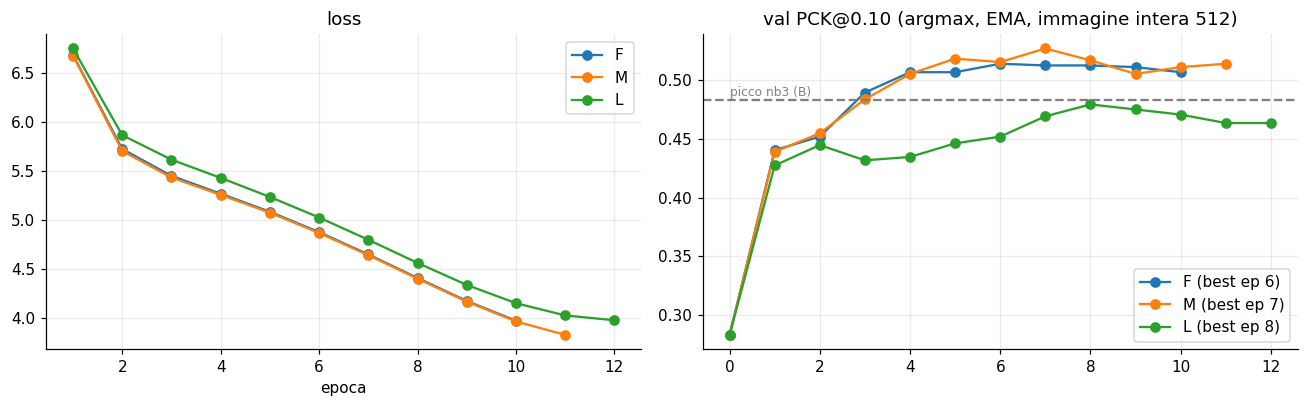

,n,PCK@0.05,PCK@0.10,PCK@0.20,CI95_10,err_median
method,,,,,,
M2 · + zoom 1 giro,695,0.391,0.604,0.755,"[0.550,0.655]",0.071
F2 · + zoom 1 giro,695,0.393,0.604,0.750,"[0.553,0.656]",0.070
L2 · + zoom 1 giro,695,0.378,0.557,0.708,"[0.508,0.607]",0.077
F1 · soft + multiscala,695,0.340,0.550,0.754,"[0.498,0.601]",0.082
M1 · soft + multiscala,695,0.345,0.548,0.755,"[0.494,0.603]",0.086
M0 · argmax 512,695,0.291,0.537,0.741,"[0.489,0.588]",0.093
F0 · argmax 512,695,0.291,0.522,0.731,"[0.473,0.571]",0.096
L1 · soft + multiscala,695,0.328,0.517,0.683,"[0.471,0.558]",0.091
L0 · argmax 512,695,0.275,0.496,0.671,"[0.452,0.538]",0.102


,PCK@0.10 val
[B nb3] zero-shot argmax 512,0.245
[B nb3] fine-tuned argmax 512,0.489
[B nb3] soft + multiscala,0.501
[B nb3] + zoom 1 giro,0.535


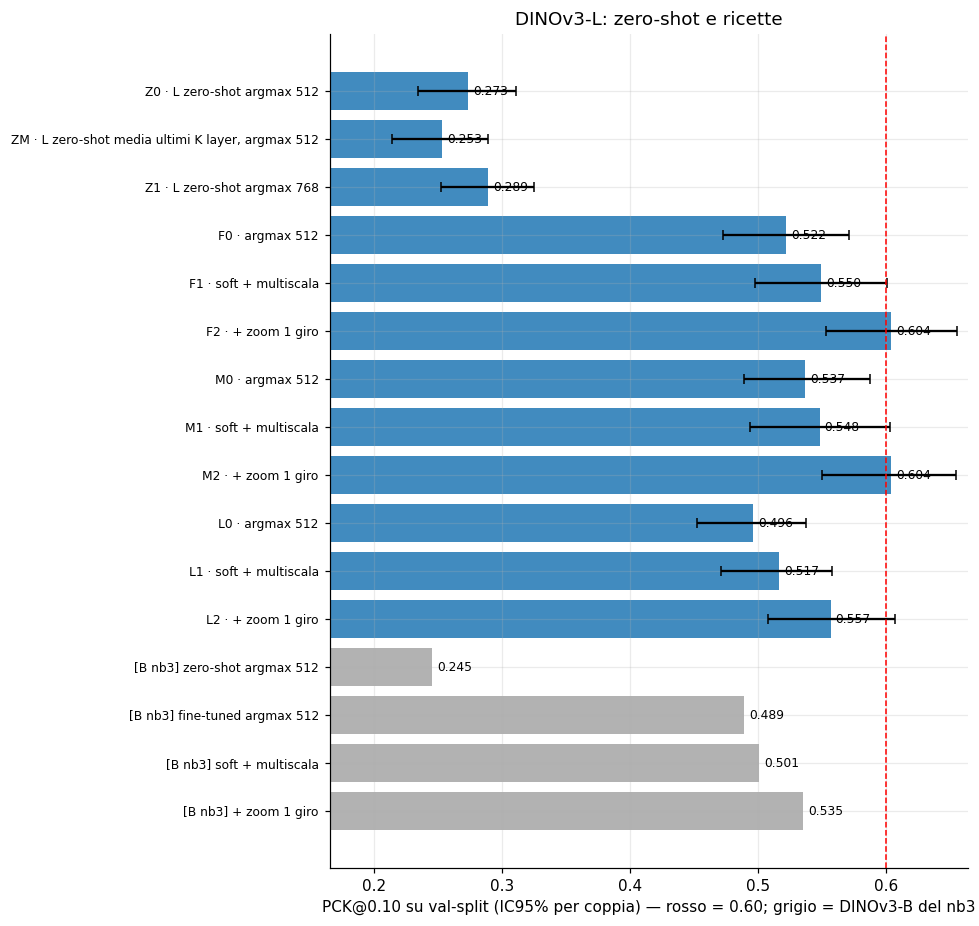

MIGLIORE: F2 · + zoom 1 giro | ricetta F | cfg {'sizes': (512, 768), 'decode': 'soft', 'tau': 0.03, 'rad': 3, 'zoom': {'margin': 0.3, 'max_frac': 0.9, 'sizes': (512, 768)}}


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for rec, H in HISTS.items(): ax[0].plot(H["ep"][1:], H["loss"][1:], "o-", label=rec); ax[1].plot(H["ep"], H["val"], "o-", label=f"{rec} (best ep {BEST_EP[rec]})")
ax[0].set_title("loss"); ax[0].set_xlabel("epoca"); ax[1].set_title("val PCK@0.10 (argmax, EMA, immagine intera 512)"); ax[1].axhline(.483, ls="--", c="gray"); ax[1].text(0, .486, "picco nb3 (B)", fontsize=8, color="gray")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
allrun = [n for r in RUN_RECIPES for n in RNAMES[r]]; zs = [n for n in RESULTS if n.startswith(("Z0", "ZM", "Z1"))]
display(summarize(zs + allrun).sort_values("PCK@0.10", ascending=False).style.format(precision=3).background_gradient(subset=["PCK@0.10"], cmap="Greens"))
display(pd.DataFrame({"PCK@0.10 val": REF_B}).style.format(precision=3).set_caption("riferimento DINOv3-B (nb3)"))
plot_summary(zs + allrun, "DINOv3-L: zero-shot e ricette", extra=REF_B)
FINAL_NAME = best_of(allrun); FINAL_CFG, FINAL_ENG = CFGS[FINAL_NAME]; BEST_REC = FINAL_NAME[0] if FINAL_NAME[:2] != "LM" else "LM"
print("MIGLIORE:", FINAL_NAME, "| ricetta", BEST_REC, "| cfg", FINAL_CFG)

## 9. Diagnostica sul metodo migliore
Confronto con i numeri del nb3 (DINOv3-B, stesso val-split): gap train/val 0.934 vs 0.535; per scala piccolo/medio/grande 0.620/0.443/0.519; 1 target / >1 target 0.486/0.613; oracolo top-K 0.512/0.645/0.686/0.753; errori 372/88/131/104 (corretto / vicino / parte sbagliata / altrove).

TRAIN-SUB · migliore:   0%|          | 0/30 [00:00<?, ?it/s]

,set,n,PCK@0.05,PCK@0.10,PCK@0.20
method,,,,,
F2 · + zoom 1 giro,val,695,0.393,0.604,0.750
TRAIN-SUB · migliore,train (sottoinsieme),183,0.913,0.973,0.978


nb3 (DINOv3-B, full fine-tuning): train 0.934 vs val 0.535 → se il gap qui è minore, la ricetta regolarizza meglio.


,gruppo,valore,n,L_zeroshot,L_argmax512,L_migliore,B_nb3_finale
0,scala oggetto,medio,201,0.229,0.448,0.453,0.443
1,scala oggetto,grande,231,0.203,0.623,0.667,0.519
2,scala oggetto,piccolo,263,0.369,0.490,0.665,0.620
3,n. target,1 target,426,0.239,0.448,0.552,0.486
4,n. target,>1 target,269,0.327,0.639,0.688,0.613


oracolo top-K (L, stadio 1): {1: 0.548, 3: 0.66, 5: 0.712, 10: 0.781} | nb3 B: {1: 0.512, 3: 0.645, 5: 0.686, 10: 0.753}


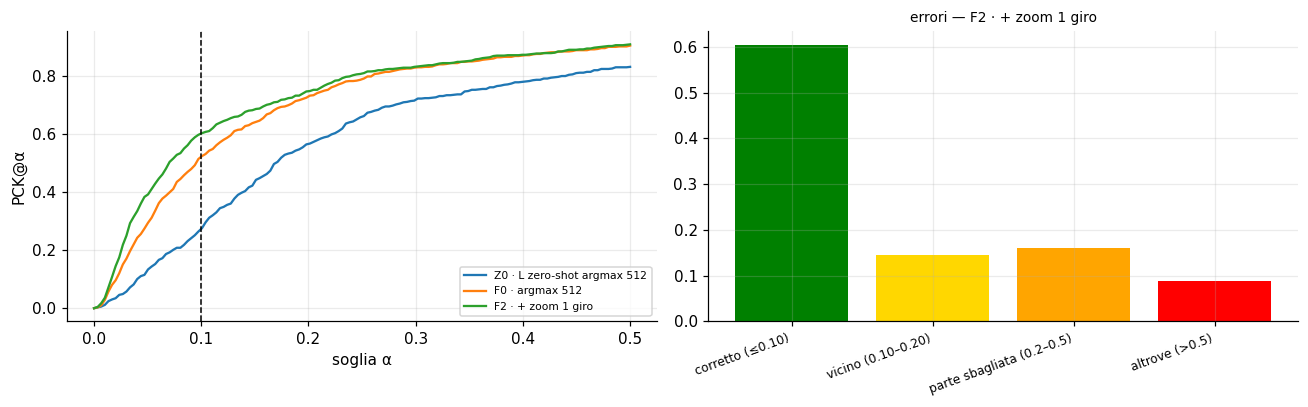

corretto (≤0.10)             420
vicino (0.10–0.20)           101
parte sbagliata (0.2–0.5)    112
altrove (>0.5)                62


In [11]:
# 1) gap train vs val
sub_p = FIT_DF.pair_id.drop_duplicates().sample(min(30, FIT_DF.pair_id.nunique()), random_state=0); TRSUB_DF = FIT_DF[FIT_DF.pair_id.isin(sub_p)]; TRSUB_MASK = tr.index.isin(TRSUB_DF.index)
run("TRAIN-SUB · migliore", FINAL_CFG, FINAL_ENG, df=TRSUB_DF)
gap = pd.concat([summarize([FINAL_NAME]).assign(set="val"), summarize(["TRAIN-SUB · migliore"], mask=TRSUB_MASK).assign(set="train (sottoinsieme)")])[["set", "n", "PCK@0.05", "PCK@0.10", "PCK@0.20"]]
display(gap.style.format(precision=3)); print("nb3 (DINOv3-B, full fine-tuning): train 0.934 vs val 0.535 → se il gap qui è minore, la ricetta regolarizza meglio.")
# 2) per scala e n. target
e_all = {n: RESULTS[n][VAL_MASK] for n in ("Z0 · L zero-shot argmax 512", RNAMES[BEST_REC][0], FINAL_NAME)}; rs = tr.rel_scale[VAL_MASK]
terc = pd.qcut(rs, 3, labels=["piccolo", "medio", "grande"]); nt = pd.Series(np.where(tr.n_targets[VAL_MASK] == 1, "1 target", ">1 target"), index=rs.index)
REFB_GRP = {"piccolo": .620, "medio": .443, "grande": .519, "1 target": .486, ">1 target": .613}; rows = []
for gname, grp in (("scala oggetto", terc.astype(str)), ("n. target", nt)):
    for g in pd.unique(grp):
        m = (grp == g).values; rows.append(dict(gruppo=gname, valore=g, n=int(m.sum()), L_zeroshot=float((e_all["Z0 · L zero-shot argmax 512"][m].dropna() <= .1).mean()),
                                              L_argmax512=float((e_all[RNAMES[BEST_REC][0]][m].dropna() <= .1).mean()), L_migliore=float((e_all[FINAL_NAME][m].dropna() <= .1).mean()), B_nb3_finale=REFB_GRP.get(g, np.nan)))
display(pd.DataFrame(rows).style.format(precision=3))
# 3) oracolo top-K (stadio 1, senza zoom)
@torch.no_grad()
def oracle_topk(df, eng, cfg, Ks=(1, 3, 5, 10)):
    res = {K: [] for K in Ks}
    for pid in df.pair_id.unique():
        pair = PAIRS_TR[pid]; maps = pair_maps(pair, eng, cfg); Wt, Ht = pair["target_size"]
        for i, r in df[df.pair_id == pid].iterrows():
            S = maps[r.query_index]; xy = [cell_to_xy(a, b, *S.shape, Wt, Ht) for a, b, _ in top_peaks(S, max(Ks), 6)]; errs = [norm_err(p, r.targets, r.scale) for p in xy]
            for K in Ks: res[K].append(min(errs[:K]) <= .1)
    return {K: round(float(np.mean(v)), 3) for K, v in res.items()}
print("oracolo top-K (L, stadio 1):", oracle_topk(VAL_DF, FINAL_ENG, dict(FINAL_CFG, zoom=None)), "| nb3 B: {1: 0.512, 3: 0.645, 5: 0.686, 10: 0.753}")
# 4) curva e tassonomia
e = RESULTS[FINAL_NAME][VAL_MASK].dropna(); xs = np.linspace(0, .5, 150); fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for n in dict.fromkeys(["Z0 · L zero-shot argmax 512", RNAMES[BEST_REC][0], FINAL_NAME]): ax[0].plot(xs, [(RESULTS[n][VAL_MASK].dropna() <= x).mean() for x in xs], label=n)
ax[0].axvline(.1, c="k", ls="--", lw=1); ax[0].set_xlabel("soglia α"); ax[0].set_ylabel("PCK@α"); ax[0].legend(fontsize=7)
cat = pd.cut(e, [-1, .1, .2, .5, 1e9], labels=["corretto (≤0.10)", "vicino (0.10–0.20)", "parte sbagliata (0.2–0.5)", "altrove (>0.5)"]).value_counts(sort=False)
ax[1].bar(range(len(cat)), cat.values / cat.sum(), color=["g", "gold", "orange", "r"]); ax[1].set_xticks(range(len(cat))); ax[1].set_xticklabels(cat.index, rotation=20, ha="right", fontsize=8); ax[1].set_title(f"errori — {FINAL_NAME}", fontsize=9)
plt.tight_layout(); plt.show(); print(cat.to_string())

## 10. Submission (testa del train-split, nessun ri-addestramento)
Si usa direttamente la **testa validata** (snapshot dell'epoca migliore) con la configurazione migliore sul val. Nel nb3 il ri-addestramento su train+val con schedule compressa portava il modello nel regime di overfitting.

In [ ]:
FINAL_REC = "F"          # "M" se preferisci M (stesso PCK sul val: 0.604)
ck = f"{WORK_DIR}/headL_{FINAL_REC}.pt"   # cambia path se il file sta altrove
assert os.path.exists(ck), f"checkpoint mancante: {ck}"
h = Head(TRUNK, **RECIPES[FINAL_REC]).to(DEVICE)
h.load_state_dict(torch.load(ck, map_location=DEVICE))
FINAL_ENG = Engine(h.eval())
FINAL_CFG = dict(BASE, zoom=ZOOM1)
print("pronto:", FINAL_REC, FINAL_CFG)

In [10]:
test_pairs = list(te.pair_id.unique())[: (4 if QUICK else None)]; rows = []
for pid in tqdm(test_pairs, desc="test"):
    pair = PAIRS_TE[pid]; out = predict_pair_zoom(pair, FINAL_ENG, FINAL_CFG); Wt, Ht = pair["target_size"]
    for r in te[te.pair_id == pid].itertuples(): x, y = out[r.query_index]; rows.append((r.id, float(np.clip(x, 0, Wt - 1)), float(np.clip(y, 0, Ht - 1))))
pred = pd.DataFrame(rows, columns=["id", "x", "y"]); pred.to_csv(f"{WORK_DIR}/predictions.csv", index=False)
def make_submission(pred, test, out_path):
    assert set(pred.columns) == {"id", "x", "y"} and not pred.id.duplicated().any() and len(pred) == len(test) and set(pred.id) == set(test.id)
    xy = pred.set_index("id").loc[test.id, ["x", "y"]].to_numpy(float); assert np.isfinite(xy).all()
    pd.DataFrame({"id": test.id, "prediction": [json.dumps(v.tolist()) for v in xy]}).to_csv(out_path, index=False)
if not QUICK:
    make_submission(pred, te, f"{WORK_DIR}/submission.csv"); sub = pd.read_csv(f"{WORK_DIR}/submission.csv")
    print(sub.head(3)); print("righe:", len(sub), "| formato ok:", all(isinstance(json.loads(p), list) and len(json.loads(p)) == 2 for p in sub.prediction))
    sp = f"{DATA_DIR}/sample_submission.csv"
    if os.path.exists(sp): print("ID identici al sample_submission:", set(pd.read_csv(sp).id) == set(sub.id))
else: print("[QUICK] submission non scritta; predizioni di prova in", f"{WORK_DIR}/predictions.csv")

test:   0%|          | 0/98 [00:00<?, ?it/s]

             id                                prediction
0  test_q_00341  [45.208812936616596, 242.92630627434198]
1  test_q_00212   [246.8935589787725, 117.51582348415414]
2  test_q_00426  [322.31627039606246, 376.63509462062973]
righe: 577 | formato ok: True
ID identici al sample_submission: True


## 11. Cosa incollare dopo il run
(1) log di training di ogni ricetta (loss, val, tempo per epoca, epoca dello snapshot, parametri addestrabili), (2) pesi α del mix, (3) la tabella finale + il grafico, (4) la diagnostica (gap train/val, per scala, oracolo, errori), (5) il punteggio della leaderboard.

**Come leggere il risultato** (IC95% ≈ ±4.8 su 102 coppie, quindi solo differenze > ~5 punti sono affidabili):
* L-zero-shot ≫ B-zero-shot (0.245) → il backbone più grande generalizza meglio; se L-fine-tuned ≈ B-fine-tuned (0.535) il fine-tuning satura sul numero di dati, non sul backbone.
* M > F → il mix dei layer porta precisione; α lontani da 0 sui layer intermedi lo confermano.
* L > F con gap train/val minore → l'overfitting è il vincolo e conviene la LoRA (poi si può alzare K).
* Se nessuna ricetta supera ~0.55: il limite è semantico (errori > 0.2) → passo successivo: selettore di candidati (oracolo top-5) e feature complementari (Stable Diffusion).